In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [34]:
data=pd.read_csv("sales_data_sample.csv",encoding='latin')

In [10]:
df=data[['QUANTITYORDERED','PRICEEACH','']]

In [12]:
scaler=StandardScaler()
scaled_data=scaler.fit_transform(df)

In [17]:
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,init='k-means++',random_state=42)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

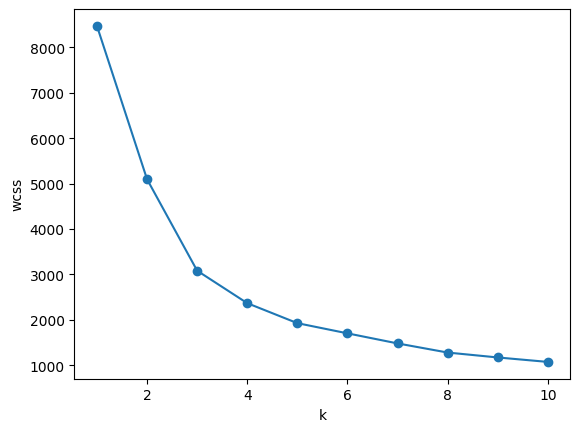

In [23]:
plt.plot(range(1,11),wcss, marker='o')
plt.xlabel('k')
plt.ylabel('wcss')
plt.show()

In [27]:
kmeans=KMeans(n_clusters=3,init='k-means++',random_state=42)
df['Clusters']=kmeans.fit_predict(scaled_data)


In [31]:
print(kmeans.cluster_centers_)
print(df.head())

[[ 0.00340709 -1.31519107 -0.83846133]
 [ 0.89846585  0.64278204  1.10107381]
 [-0.79188456  0.55612886 -0.2525054 ]]
   QUANTITYORDERED  PRICEEACH    SALES  Clusters
0               30      95.70  2871.00         2
1               34      81.35  2765.90         2
2               41      94.74  3884.34         1
3               45      83.26  3746.70         1
4               49     100.00  5205.27         1


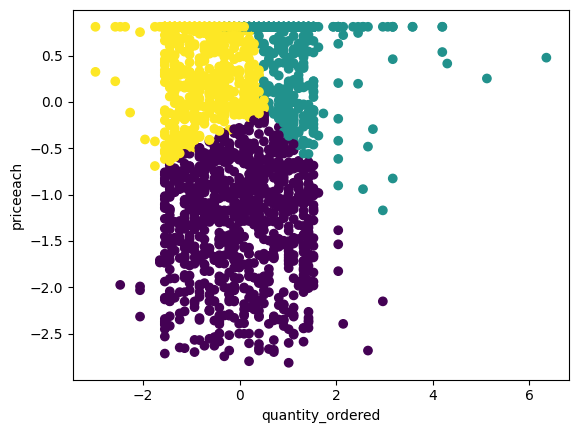

In [33]:
plt.scatter(scaled_data[:,0],scaled_data[:,1],c=df['Clusters'])
plt.xlabel('quantity_ordered')
plt.ylabel('priceeach')

plt.show()
